In [1]:
import pysvorbit
import matplotlib.pyplot as plt
import numpy as np
from backend import _solve_kepler

In [2]:
# Sampling points for get_sky_projected_orbit function
num_points = 10000

# Sky projected orbit plotter function
def get_sky_projected_orbit(a, e, i, omega, Omega, num_points):

    # Computes sky-projected coordinates (X, Y) from Keplerian elements. Angles (i, omega, Omega) should be in degrees.
    
    # Convert angles to radians
    i_rad = np.radians(i)
    omega_rad = np.radians(omega)
    Omega_rad = np.radians(Omega)
    
    # 1. Sample true anomalies across a full orbit
    nu = np.linspace(0, 2 * np.pi, num_points)
    
    # 2. Distance 'r' from the focus for an ellipse
    r = (a * (1 - e**2)) / (1 + e * np.cos(nu))
    
    # Position vectors in the intrinsic orbital plane
    x_prime = r * np.cos(nu)
    y_prime = r * np.sin(nu)
    
    # 3. Apply Thiele-Innes or standard rotation matrix combinations
    # X (East) and Y (North) positions projected on the plane of the sky
    X = x_prime * (np.cos(omega_rad) * np.sin(Omega_rad) + np.sin(omega_rad) * np.cos(Omega_rad) * np.cos(i_rad)) + \
        y_prime * (-np.sin(omega_rad) * np.sin(Omega_rad) + np.cos(omega_rad) * np.cos(Omega_rad) * np.cos(i_rad))
        
    Y = x_prime * (np.cos(omega_rad) * np.cos(Omega_rad) - np.sin(omega_rad) * np.sin(Omega_rad) * np.cos(i_rad)) + \
        y_prime * (-np.sin(omega_rad) * np.cos(Omega_rad) - np.cos(omega_rad) * np.sin(Omega_rad) * np.cos(i_rad))
        
    return X, Y



def sky_position_at_epoch(t, P, T, e, a, i, omega, Omega):
    """
    Model position on the sky at epoch(s) t, using the same projection as
    get_sky_projected_orbit(). 'a' in the units you want back (mas here);
    angles in degrees; t, T, P all in years.
    Returns (North, East) so it plots directly on your (x = North, y = East) axes.
    """
    t = np.atleast_1d(np.asarray(t, dtype=float))
 
    # Mean anomaly at each epoch
    M = 2 * np.pi * (((t - T) / P) % 1.0)
 
    # Eccentric anomaly from PySVOrbit's own Kepler solver (one epoch at a time)
    E = np.array([_solve_kepler(m, e) for m in M])
 
    # Safety check: _solve_kepler can occasionally diverge at very high e
    bad = np.abs(E - e * np.sin(E) - M) > 1e-6
    if bad.any():
        raise RuntimeError(f"_solve_kepler did not converge for epoch(s) {t[bad]}")
 
    # True anomaly and orbital radius
    nu = 2 * np.arctan2(np.sqrt(1 + e) * np.sin(E / 2), np.sqrt(1 - e) * np.cos(E / 2))
    r = a * (1 - e**2) / (1 + e * np.cos(nu))
    xp, yp = r * np.cos(nu), r * np.sin(nu)
 
    io, wo, Oo = np.radians([i, omega, Omega])
    East = xp * (np.cos(wo) * np.sin(Oo) + np.sin(wo) * np.cos(Oo) * np.cos(io)) + \
           yp * (-np.sin(wo) * np.sin(Oo) + np.cos(wo) * np.cos(Oo) * np.cos(io))
    North = xp * (np.cos(wo) * np.cos(Oo) - np.sin(wo) * np.sin(Oo) * np.cos(io)) + \
            yp * (-np.sin(wo) * np.cos(Oo) - np.cos(wo) * np.sin(Oo) * np.cos(io))
    return North, East


Position measures: 7
RV measures: 714, 615
Fitting 10 elements: ['P', 'T', 'e', 'a', 'W', 'w', 'i', 'K1', 'K2', 'V0']
Total observations: 1343 (npos=7, nrv1=714, nrv2=615)
`xtol` termination condition is satisfied.
Function evaluations 6, initial cost 5.0846e+06, final cost 2.1127e+06, first-order optimality 1.31e+03.
Degrees of freedom: 1333
Chi-squared: 4225336.7262, Reduced Chi-squared: 3169.7950
Jacobian shape: (1343, 10)
JTJ condition number: 5.11e+15
Error computing covariance: normal matrix is effectively singular (condition number 5.11e+15)
Using approximate unscaled errors
CHI2/N: ['0.8202', '0.3351', '5878.5680', '45.5790']
RMS (Theta, rho, RV1, RV2): 1.3379, 0.0017, 0.4319, 0.2454

Initial Parameters (from input file):
P    :     2.4362
T    :  2007.2597
e    :     0.9761
a    :     0.1074
W    :   272.8000
w    :   255.6900
i    :    55.4000

Initial Mass Estimates:
 Total mass (from a, P, π): 1.560 solar masses

Initial Spectroscopic Mass Estimates:
  M(1+2)·sin³i   = 0.79

/Users/ethanchen/ASTRO2/ASTRO399/PySVOrbit/backend.py:641: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/ethanchen/ASTRO2/ASTRO399/PySVOrbit/backend.py:641: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


SOAR + Strass RV PySVOrbit Fit Results:

P = 2.4363465775759714 ± 0.9782285731627867
T = 2007.259596875814 ± 0.6689970053348829
e = 0.9768044159277806 ± 0.02359558658737887
a = 0.11933171061823448 ± 4.748892597767996e-09
W = 275.46654216130105 ± 7.586949270206355e-12
w = 255.7349805993806 ± 9.423135345084073e-05
i = 60.18182811267908 ± 1.9557344905461506e-10
K1 = 37.859096101997 ± 0.00013479067656549273
K2 = 57.08689811048508 ± 2.3584143383124932e-07
V0 = 7.432899851366187 ± 0.00010654422218226712


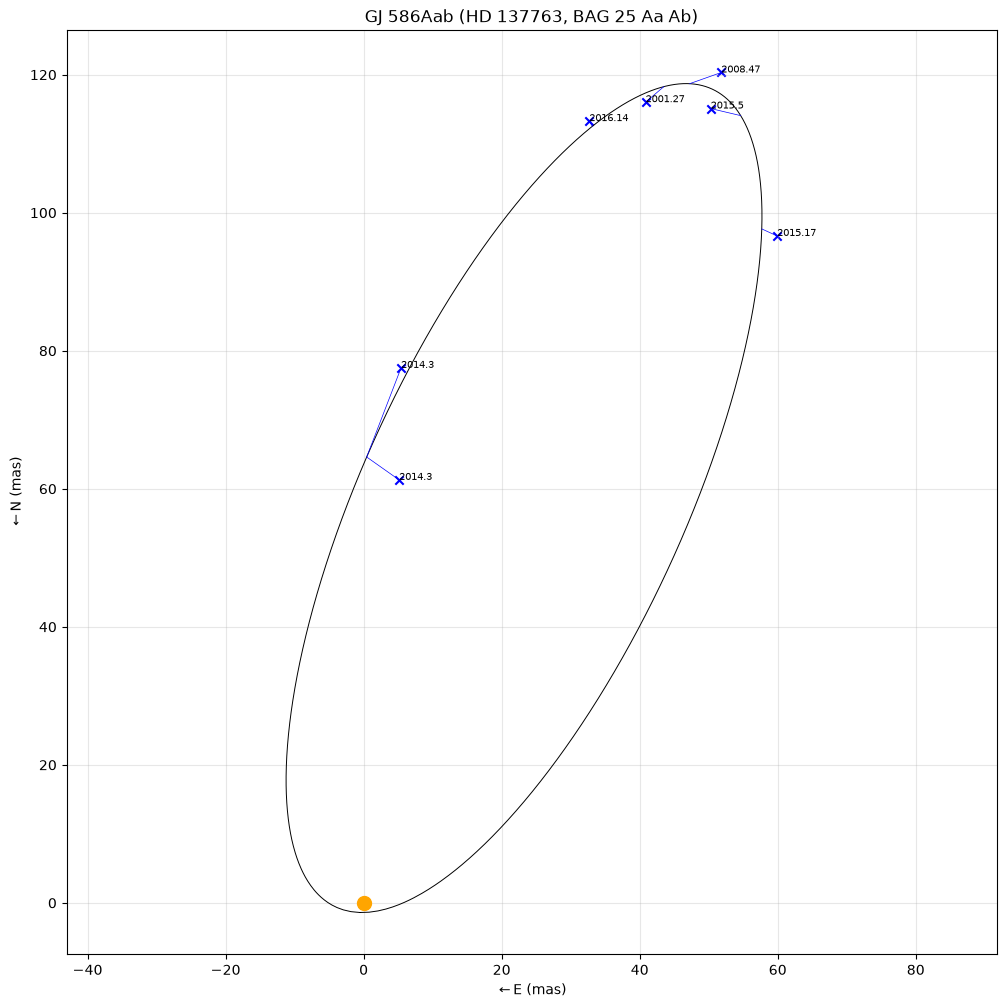

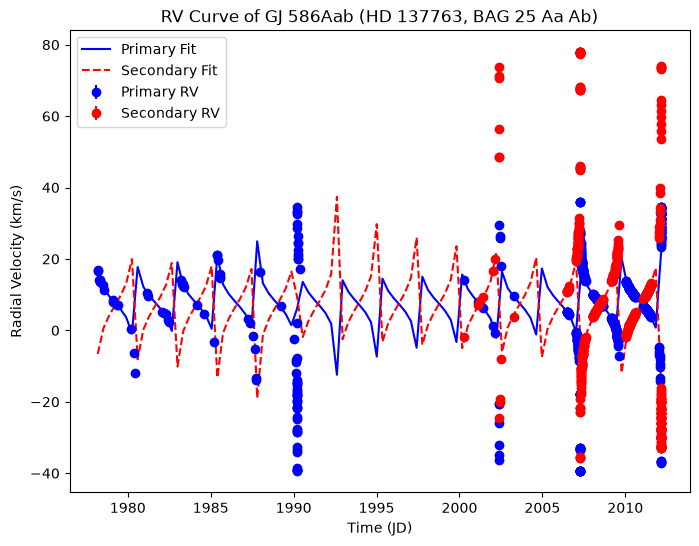

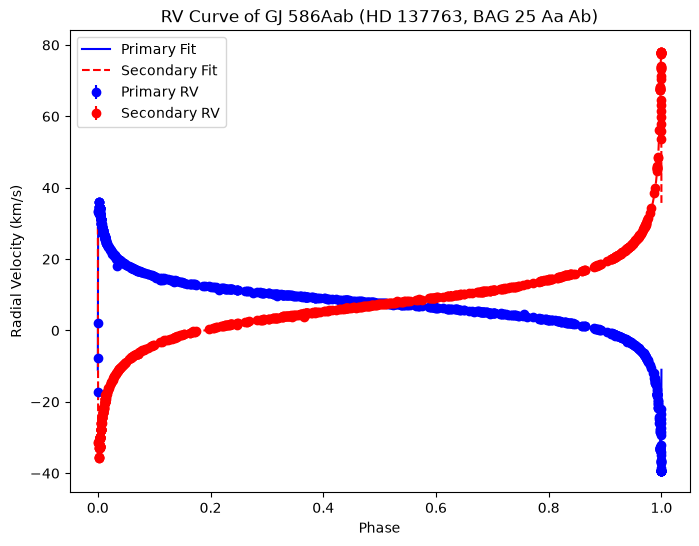

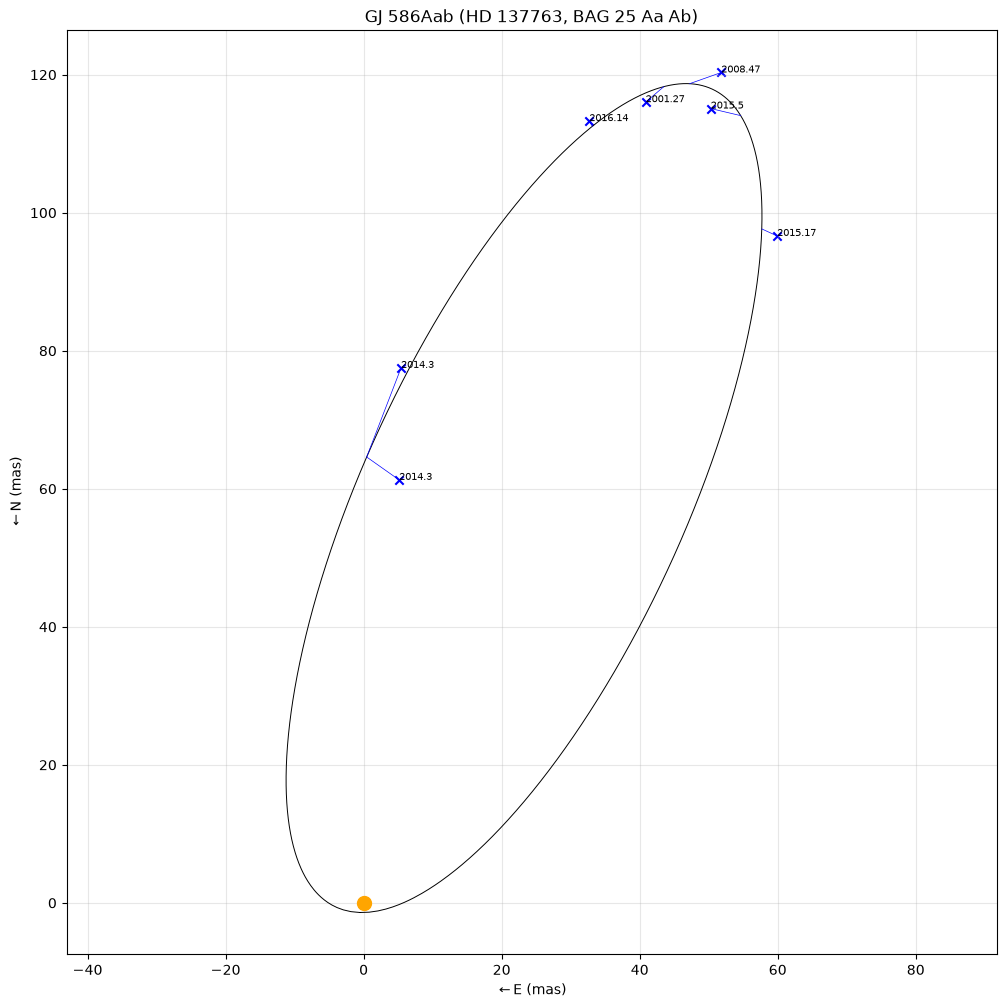

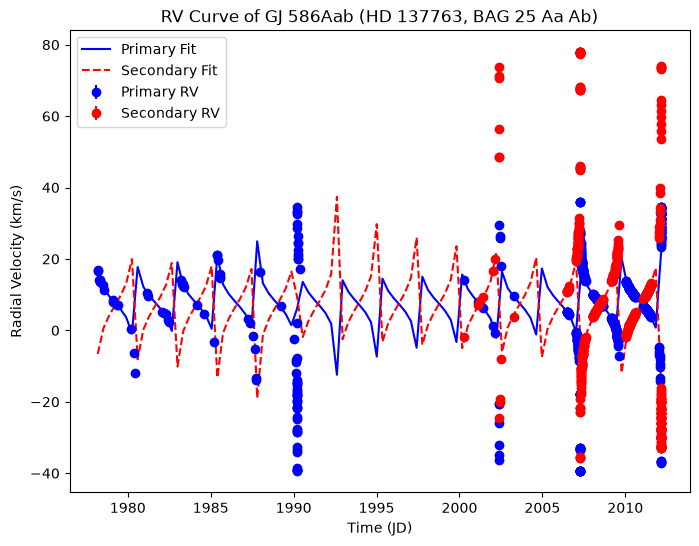

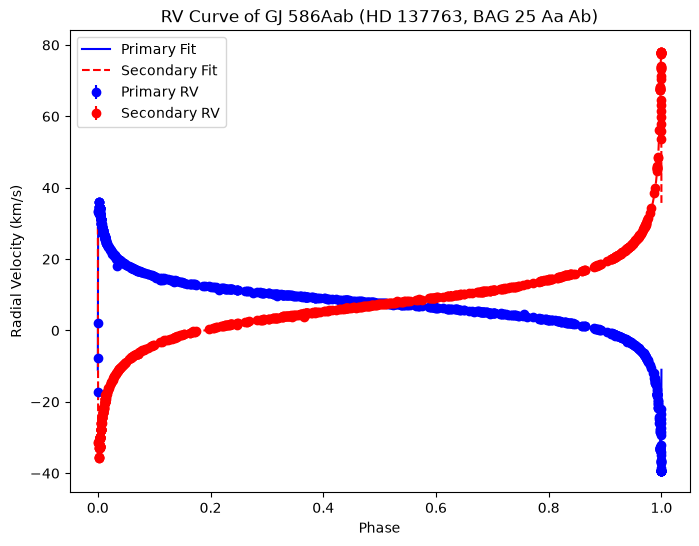

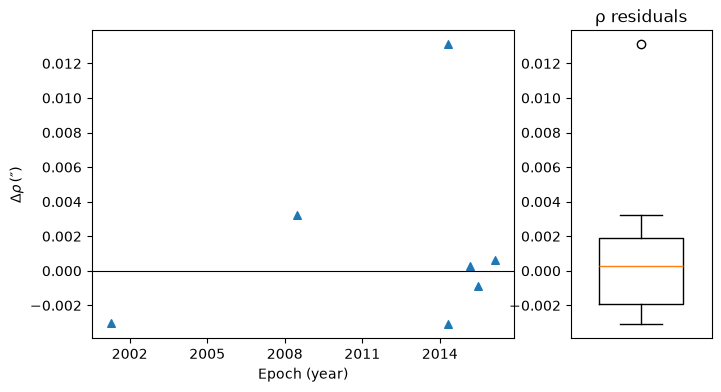

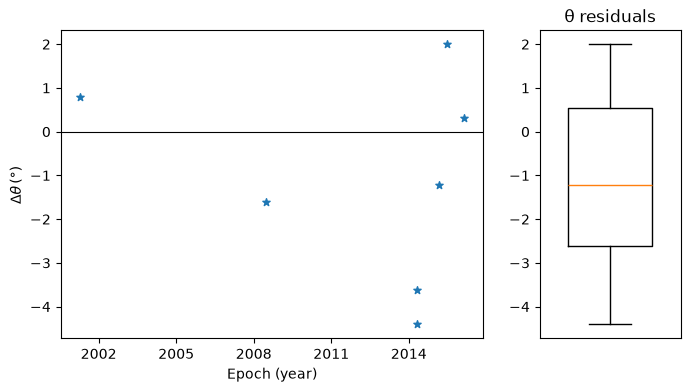

In [3]:
# Load the SOAR + Strass RV data and save its orbital elements to be plotted 
data_path = "SOAR + Strass2013RV/GJ586A_SOAR_StrassRV.inp"
pysvorbit.readinp(data_path)

# Uses scipy least_squares() to fit the orbit
pysvorbit.fitorb() 

pysvorbit.orbsave()   # writes <name>_output.csv to the working directory

pysvorbit.orbplot(ps=True) # plots fitted orbit and closes figs
pysvorbit.residual_plots()

pos = pysvorbit.orb.pos 
pos_soar = pysvorbit.orb.pos          # one row per position measurement
pa_soar = pos[:, 1].tolist()      # position angle (deg)
sep_soar = pos[:, 2].tolist()      # separation (arcsec)
t_obs_soar = pos[:, 0].tolist()   # epoch (decimal year)


# Values from the PySVOrbit fit on GJ586A_visual.inp
P_soar, T_soar, e_soar, a_soar, W_soar, w_soar, i_soar, K1_soar, K2_soar, V0_soar = pysvorbit.orb.el
P_err_soar, T_err_soar, e_err_soar, a_err_soar, W_err_soar, w_err_soar, i_err_soar, K1_err_soar, K2_err_soar, V0_err_soar = pysvorbit.orb.elerr
# Plot the recent PySVOrbit fit
X_SOAR, Y_SOAR = get_sky_projected_orbit(a_soar*1e3, e_soar, i_soar, w_soar, W_soar, num_points)


print("SOAR + Strass RV PySVOrbit Fit Results:\n")
for name, value, error in zip(pysvorbit.orb.elname,
                              pysvorbit.orb.el,
                              pysvorbit.orb.elerr):
    print(f"{name} = {value} ± {error}")


In [4]:
# Load the MIRC + SOAR + Strass RV data 
data_path = "SOAR + MIRC + Strass2013RV/GJ586A_SOAR_MIRC_StrassRV.inp"
pysvorbit.readinp(data_path)



Position measures: 10
RV measures: 714, 615


Fitting 10 elements: ['P', 'T', 'e', 'a', 'W', 'w', 'i', 'K1', 'K2', 'V0']
Total observations: 1349 (npos=10, nrv1=714, nrv2=615)
`xtol` termination condition is satisfied.
Function evaluations 6, initial cost 5.0872e+06, final cost 2.1128e+06, first-order optimality 1.31e+03.
Degrees of freedom: 1339
Chi-squared: 4225622.8798, Reduced Chi-squared: 3155.8050
Jacobian shape: (1349, 10)
JTJ condition number: 6.22e+13
Covariance matrix computed successfully (not rescaled by reduced chi-square)
CHI2/N: ['2.0991', '27.3262', '5878.5662', '45.5810']
RMS (Theta, rho, RV1, RV2): 0.0818, 0.0001, 0.4319, 0.2454

Initial Parameters (from input file):
P    :     2.4362
T    :  2007.2597
e    :     0.9761
a    :     0.1074
W    :   272.8000
w    :   255.6900
i    :    55.4000

Initial Mass Estimates:
 Total mass (from a, P, π): 1.560 solar masses

Initial Spectroscopic Mass Estimates:
  M(1+2)·sin³i   = 0.797844 solar masses
  M₁             = 0.857306 solar masses
  M₂             = 0.573244 solar

/Users/ethanchen/ASTRO2/ASTRO399/PySVOrbit/backend.py:641: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
/Users/ethanchen/ASTRO2/ASTRO399/PySVOrbit/backend.py:641: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


(<Figure size 800x400 with 2 Axes>, <Figure size 800x400 with 2 Axes>)

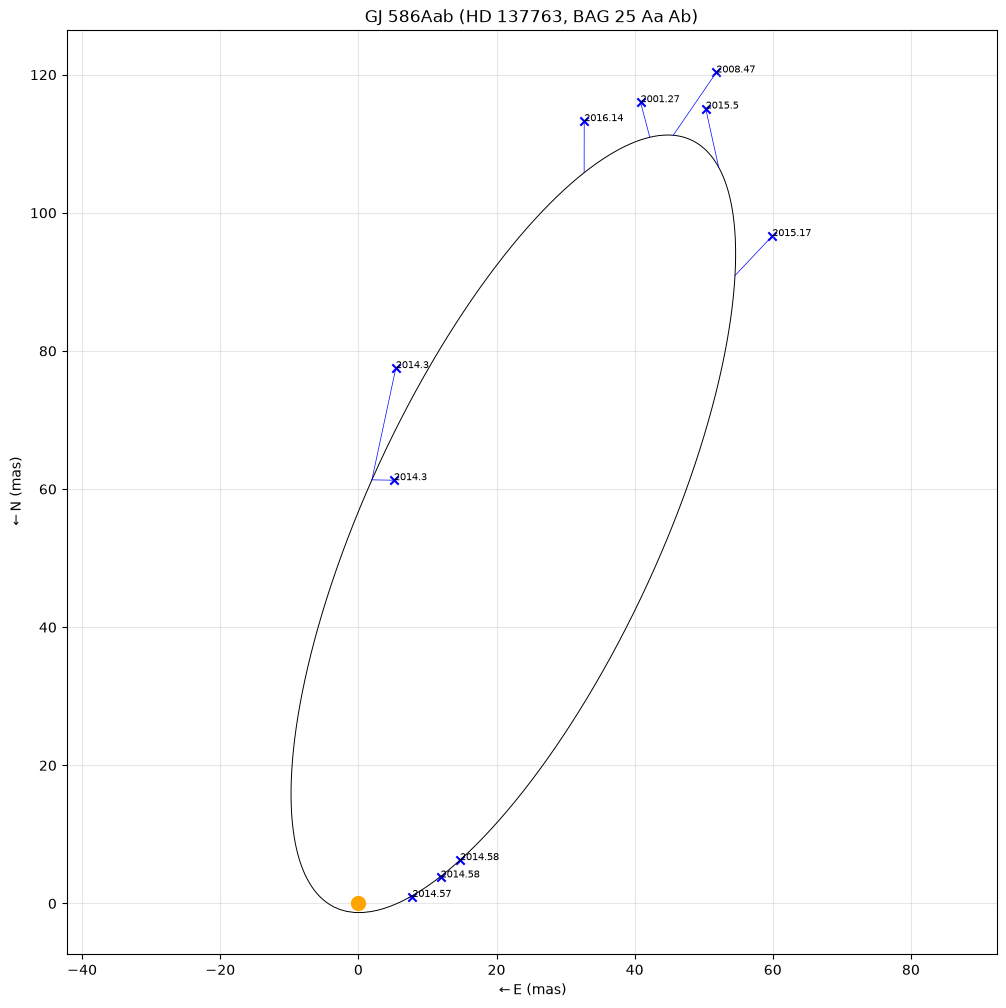

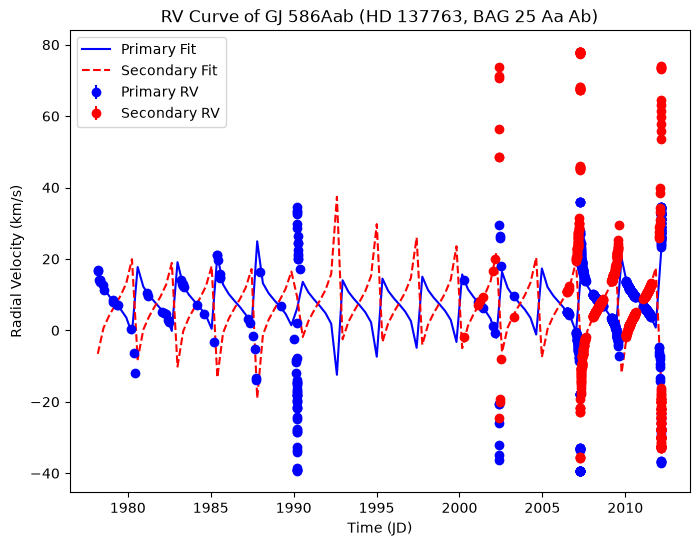

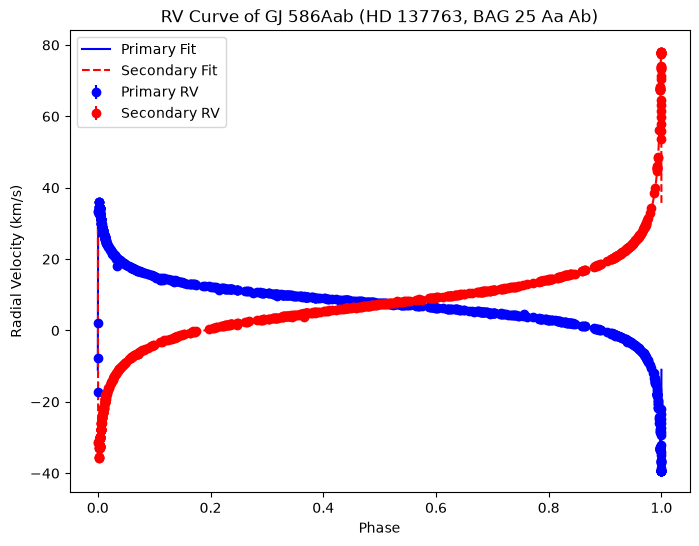

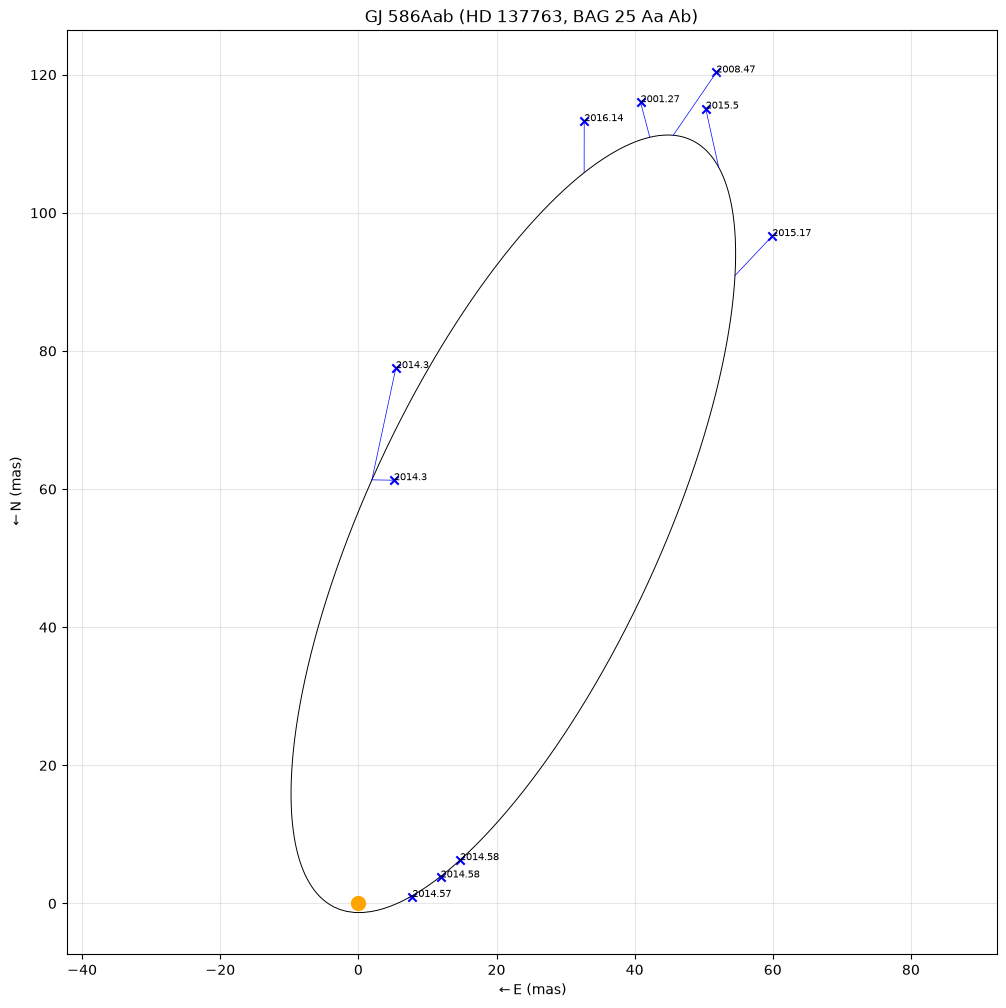

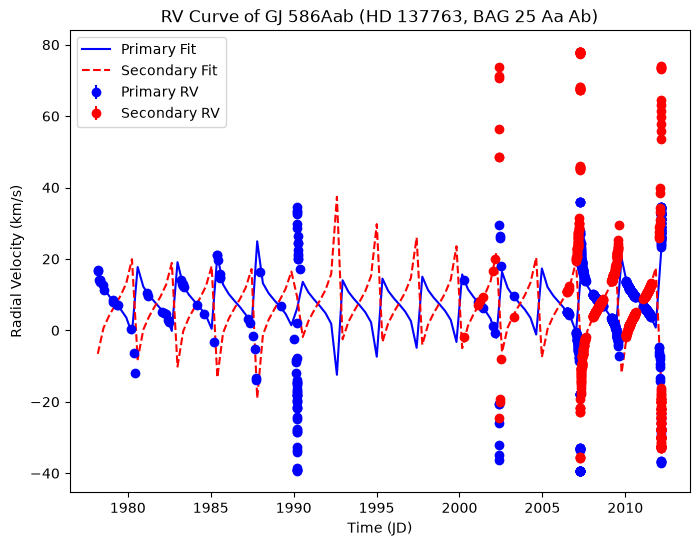

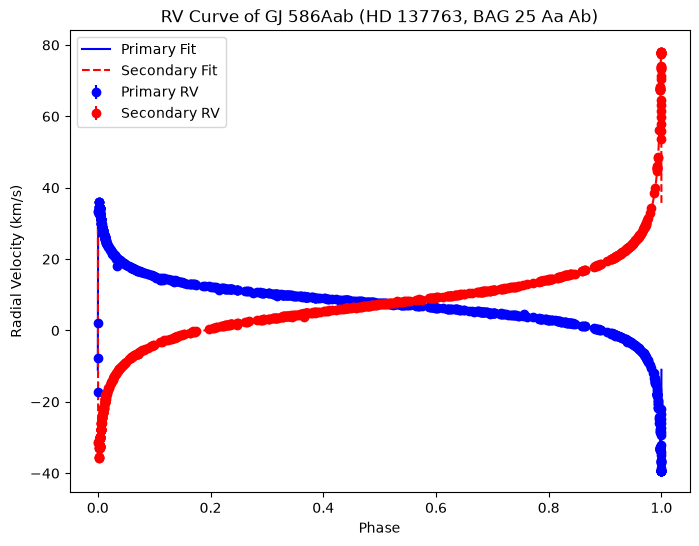

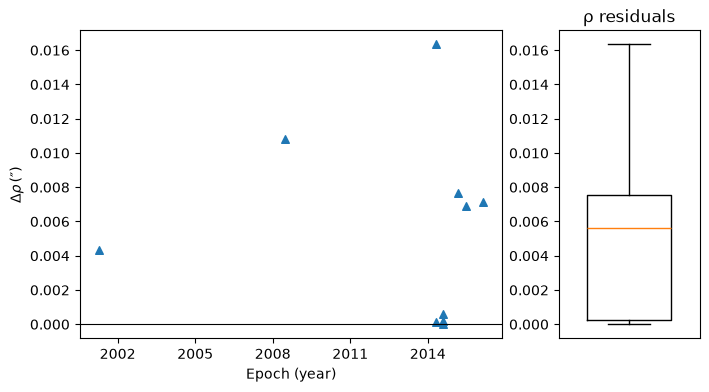

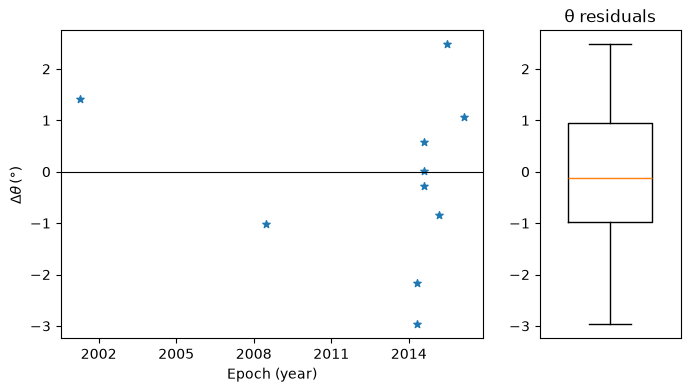

In [5]:
# Uses scipy least_squares() to fit the orbit
pysvorbit.fitorb() 

pysvorbit.orbsave()   # writes <name>_output.csv to the working directory

pysvorbit.orbplot(ps=True) # plots fitted orbit and closes figs
pysvorbit.residual_plots()

In [6]:
plt.close('all')

In [7]:
# Values from the PySVOrbit fit on GJ586A_visual.inp
P, T, e, a, W, w, i, K1, K2, V0 = pysvorbit.orb.el
P_err, T_err, e_err, a_err, W_err, w_err, i_err, K1_err, K2_err, V0_err = pysvorbit.orb.elerr
# Plot the recent PySVOrbit fit
X_test, Y_test = get_sky_projected_orbit(a*1e3, e, i, w, W, num_points)

In [8]:
# Load data from Tokovinin 2016 Speckle Interferometry

target = "GJ 586Aab (HD 137763, WDS 15282-0921)"
unit = 'mas' # 

data = np.genfromtxt("Obs Point Plotting CSVs/GJ586A_2016Tokovinin.csv", delimiter=",", skip_header=1, usecols = (0, 1, 2))
theta_obs_soar = np.deg2rad(data[:, 0])   # position angle, N through E
rho_obs = data[:, 1]                 # separation (arcsec)

t_obs2016 = data[:, 2]                   # epoch (decimal year)
x_obs2016 = rho_obs * np.cos(theta_obs_soar) * 1000
y_obs2016 = rho_obs * np.sin(theta_obs_soar) * 1000

# Orbital Elements from Tokovinin 2016 (HARD-CODED)

P_2016 = 2.43623
T_2016 = 2007.2603
a_2016 = 0.1074*1000      # Semi-major axis mas
e_2016 = 0.976    # Eccentricity
i_2016 = 55.4     # Inclination (degrees)
omega_2016 = 255.6  # Argument of periapsis (degrees)
Omega_2016 = 272.8  # Longitude of ascending node (degrees)
plx_2016 = 52.5 # +/- 6.2 mas
X_2016, Y_2016 = get_sky_projected_orbit(a_2016, e_2016, i_2016, omega_2016, Omega_2016, num_points)

In [9]:
# Load data from Strassmeier et al. 2013 Adaptive Optics Only (HARD CODED)
theta_2013 = [328.8, 336]
rho_2013 = [103.8, 124.7]
t_obs_2013 = [2005.331016, 2013.192881] # UNKNOWN, may have to look at the archives from the paper

x_obs2013 = rho_2013 * np.cos(np.deg2rad(theta_2013))  
y_obs2013 = rho_2013 * np.sin(np.deg2rad(theta_2013))

P_2013 = 889.81948/365.25
T_2013 = 2007.2596945205473 # Converted from  2454196.2885 using astropy 
a_2013 = 104.2      # Semi-major axis mas
e_2013 = 0.976081    # Eccentricity
i_2013 = 55.0     # Inclination (degrees)
omega_2013 = 255.69  # Argument of periapsis (degrees)
Omega_2013 = 272.7  # Longitude of ascending node (degrees)
X_2013, Y_2013 = get_sky_projected_orbit(a_2016, e_2016, i_2016, omega_2016, Omega_2016, num_points)

In [10]:
# Load observation points from PMOIRED MIRC for plotting
data_mirc = np.genfromtxt("Obs Point Plotting CSVs/GJ586A_MIRC.csv", delimiter=",", skip_header=1, usecols=(0, 1, 2))
theta_obs_mirc = np.deg2rad(data_mirc[:, 0])  # position angle, N through E
rho_obs_mirc = data_mirc[:, 1]                # separation (mas)
t_obs_mirc = data_mirc[:, 2]

x_obs_mirc = rho_obs_mirc * np.cos(theta_obs_mirc)
y_obs_mirc = rho_obs_mirc * np.sin(theta_obs_mirc)


In [11]:
# Values from GJ586A_visual.inp

# Get the list of position angles and separations from the inp file
pos = pysvorbit.orb.pos          # one row per position measurement
pa = pos[:, 1].tolist()      # position angle (deg)
sep = pos[:, 2].tolist()      # separation (arcsec)
t_obs = pos[:, 0].tolist()   # epoch (decimal year)

# Get the parallax from the inp file
plx = pysvorbit.orb.obj["parallax"]

print(pa)
print(sep)
print(t_obs)

# to mas
x_obs_test = sep * np.cos(np.deg2rad(pa)) * 1000
y_obs_test = sep * np.sin(np.deg2rad(pa)) * 1000 

[340.6, 336.7, 355.2, 356.0, 276.9459885, 287.5509577, 293.116830260094, 328.2, 336.4, 343.9]
[0.123, 0.131, 0.0615, 0.0777, 0.007858957634, 0.01248803663, 0.0159907928646592, 0.1137, 0.1256, 0.1179]
[2001.271, 2008.4716, 2014.3033, 2014.3033, 2014.57310499, 2014.57863956, 2014.5840973979023, 2015.1718, 2015.4967, 2016.1409]


In [12]:
# Other rho/sep values found
# From Horch et al. 2017 using WIYN Telescope Speckle Imaging https://arxiv.org/pdf/1703.06253

theta_other =[344.5]
rho_other = [0.1020*1e3]
t_obs_other = [2011.445]

x_obs_other = rho_other * np.cos(np.deg2rad(theta_other))  
y_obs_other = rho_other * np.sin(np.deg2rad(theta_other))  

Plot saved to orbit_plot.png
MIRC + SOAR + Strass RV PySVOrbit Fit Results:

P = 2.436346574441253 ± 1.1958862518726637e-07
T = 2007.2595968745275 ± 2.617560662566683e-07
e = 0.9768045394974108 ± 1.911328479455789e-06
a = 0.10794438042962459 ± 0.00011948639102681112
W = 273.74971784024297 ± 0.17488833646758856
w = 255.73507088141525 ± 0.0016286667002643025
i = 58.5067621299462 ± 0.34541775093568633
K1 = 37.85915556837117 ± 0.0009654480488005947
K2 = 57.08698953165921 ± 0.004886448299665635
V0 = 7.432899087329359 ± 0.00022790994834999935


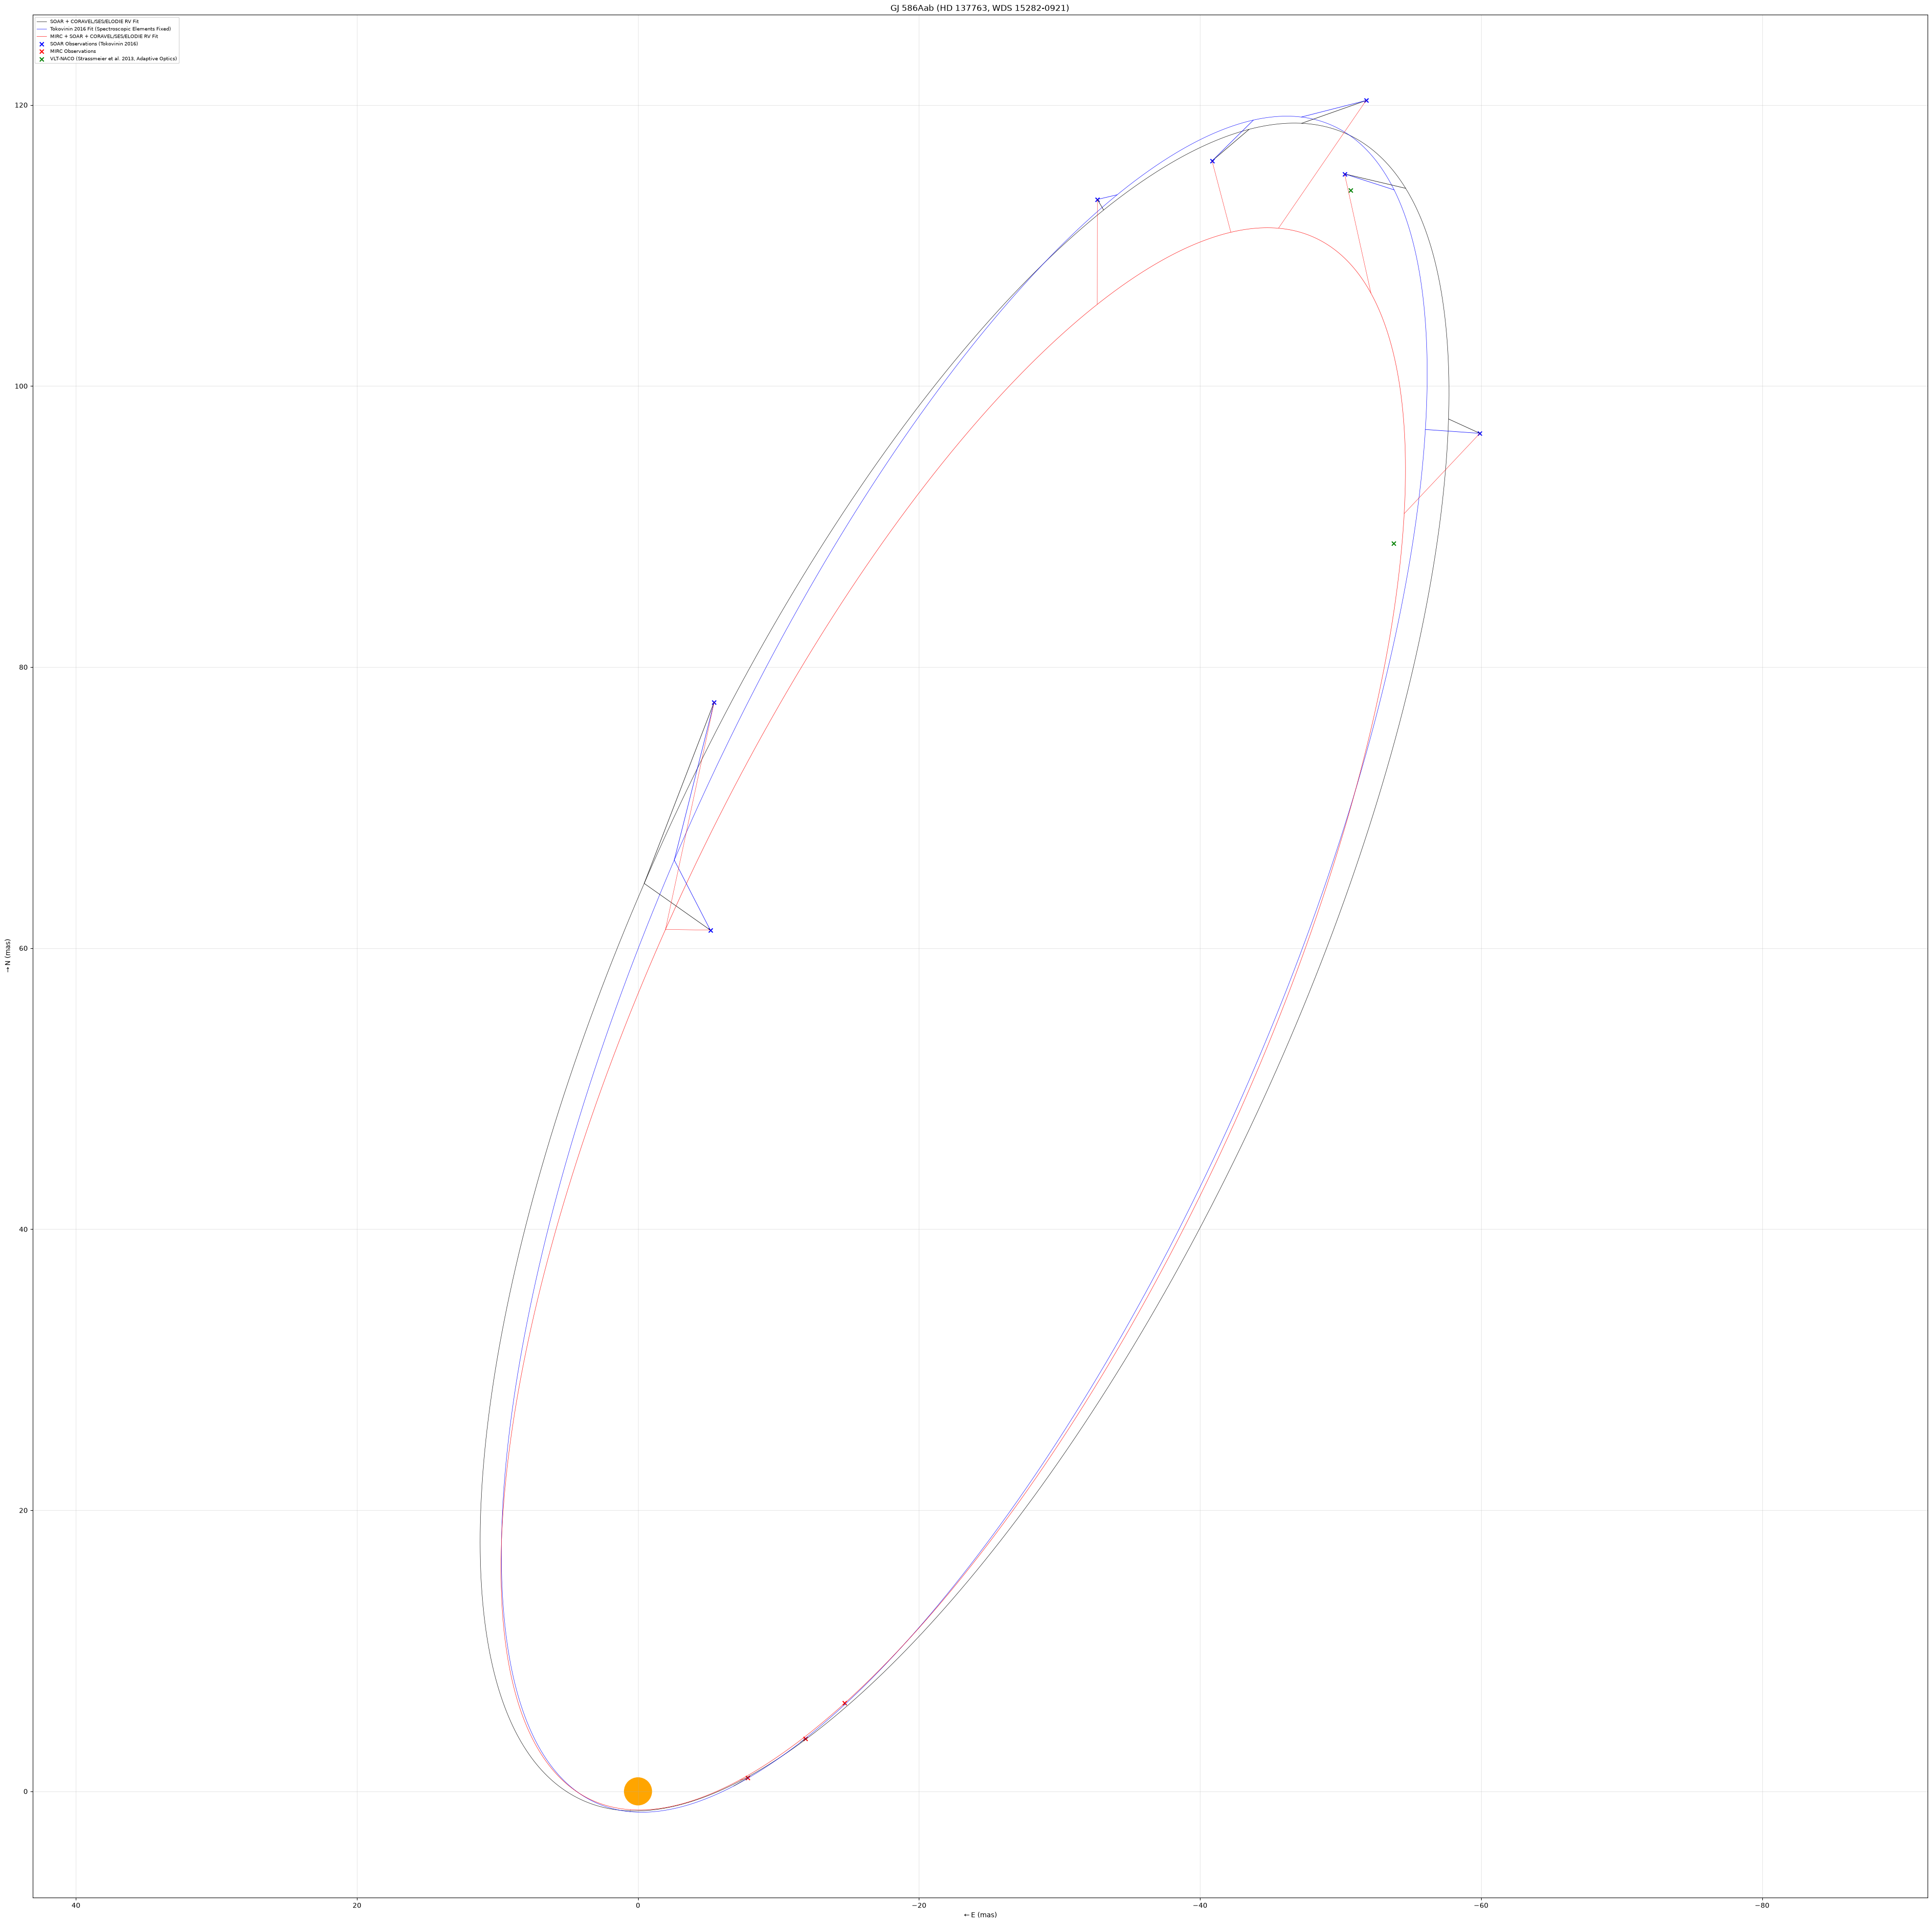

In [ ]:
# Plotting
fig, ax = plt.subplots(figsize=(10, 10))


# Plot the SOAR + Strassmeier 
ax.plot(X_SOAR, Y_SOAR, color='black', linestyle='-', lw=0.5, zorder=2, label="SOAR + CORAVEL/SES/ELODIE RV Fit")


# Plot the Tokovinin 2016 orbit fit (Speckle Interferometry)
ax.plot(X_2016, Y_2016, color='blue', linestyle='-', lw=0.5, zorder=2, label="Tokovinin 2016 Fit (Spectroscopic Elements Fixed)")


# Plot the recent PySVOrbit fit from GJ_586A_visual.inp
ax.plot(X_test, Y_test, color='red', linestyle='-', lw=0.5, label="MIRC + SOAR + CORAVEL/SES/ELODIE RV Fit")


# Plot the Strassmeier et al. 2013 orbit fit (RV + Adaptive Optics)
# plt.plot(X_2013, Y_2013, color='green', linestyle='-', lw=0.5, zorder=2)



# Plot the Tokovinin 2016 Observations (Speckle Interferometry)
ax.scatter(y_obs2016, x_obs2016, label="SOAR Observations (Tokovinin 2016)", marker = "x",color="blue")

# Plot the MIRC Observations (Long-baseline Interferometry)
ax.scatter(y_obs_mirc, x_obs_mirc, marker = "x", color="red", label="MIRC Observations")


# Plot the Stassmeier 2013 Observations (Adaptive Optics)
ax.scatter(y_obs2013, x_obs2013, label="VLT-NACO (Strassmeier et al. 2013, Adaptive Optics)", marker = "x",color="green", zorder=2)

# Plot the Horch 2017 Observations (Speckle Imaging)
#ax.scatter(y_obs_other, x_obs_other, label="WIYN (Horch et al. 2017, Speckle Imaging)", marker = "x", color="purple", zorder=2)




# Plot primary star
# Aa = plt.Circle((0, 0), 0.218879578362, facecolor='orange') # Actual angular diameter
Aa = plt.Circle((0, 0), 1, facecolor='orange') 
ax.add_patch(Aa)


# Plot residual lines for SOAR + Strass RV Observations
N_modsoar, E_modsoar = sky_position_at_epoch(t_obs_soar, P_soar, T_soar, e_soar, a_soar * 1e3, i_soar, w_soar, W_soar)
for xo, yo, xm, ym in zip(x_obs2016, y_obs2016, N_modsoar, E_modsoar):
    ax.plot([yo, ym], [xo, xm], linestyle='-', color="black", lw=0.6)


# Plot residual lines for Tokovinin 2016 Observations
N_mod2016, E_mod2016 = sky_position_at_epoch(t_obs2016, P_2016, T_2016, e_2016, a_2016, i_2016, omega_2016, Omega_2016)
for xo, yo, xm, ym in zip(x_obs2016, y_obs2016, N_mod2016, E_mod2016):
    ax.plot([yo, ym], [xo, xm], linestyle='-', color="blue", lw=0.6)

# t_obs_soar


# Plot residual lines for PySVOrbit fit
N_modtest, E_modtest = sky_position_at_epoch(t_obs, P, T, e, a * 1e3, i, w, W)
for xo, yo, xm, ym in zip(x_obs_test, y_obs_test, N_modtest, E_modtest):
    ax.plot([yo, ym], [xo, xm], linestyle='-', color="red", lw=0.4)





mirc_potential = [2014.573105, 2014.57863956, 2014.5840973979]

x_mirc_potential, y_mirc_potential = sky_position_at_epoch(mirc_potential, P_2016, T_2016, e_2016, a_2016, i_2016, omega_2016, Omega_2016)
# ax.scatter(y_mirc_potential, x_mirc_potential, marker='2', color='black', label='MIRC Epoch Predicted by Tokovinin 2016')



ax.set_title(f"{target}")
ax.set_xlabel(f"$\\leftarrow$E ({unit})")
ax.set_ylabel(f"$\\rightarrow$N ({unit})")
ax.legend(fontsize=7, loc="upper left")

ax.axis('equal')
ax.invert_xaxis()   # East to the left


# Plot Tokovinin 2016 Predictions vs MIRC Observations
for k in range(len(x_mirc_potential)):
    ax.plot([y_mirc_potential[k], y_obs_mirc[k]],
            [x_mirc_potential[k], x_obs_mirc[k]],
            linestyle='-', color='black', lw=0.4)




centerx = -5
centery = 1
half_width = 13
#ax.set_xlim(centerx+half_width, centerx-half_width)
#ax.set_ylim(centery-half_width, centery+half_width)

ax.grid(alpha=0.3)


# Astro standard, East is left, North is up
#ax.yaxis.set_inverted(True)

folder = data_path.find("/")


plt.savefig(f"{data_path[0:folder]}/orbit_plot.png")



print("Plot saved to orbit_plot.png")

print("MIRC + SOAR + Strass RV PySVOrbit Fit Results:\n")
for name, value, error in zip(pysvorbit.orb.elname,
                              pysvorbit.orb.el,
                              pysvorbit.orb.elerr):
    print(f"{name} = {value} ± {error}")

In [14]:
plt.close()

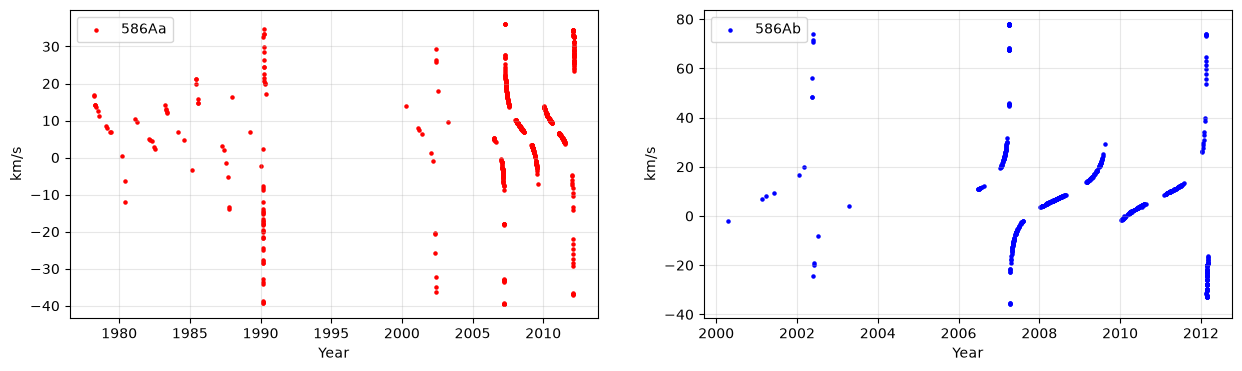

In [15]:
rv_data_a = pysvorbit.orb.rv1
rv_data_b = pysvorbit.orb.rv2


t_rv_a = rv_data_a[:, 0]
rv_a = rv_data_a[:, 1]

t_rv_b = rv_data_b[:, 0]
rv_b = rv_data_b[:, 1]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))

ax1.scatter(t_rv_a, rv_a, label = "586Aa", color = 'red',s=5)
ax2.scatter(t_rv_b, rv_b, label = "586Ab", color = 'blue', s=5)
#plt.axis('equal')

ax1.set_xlabel("Year")
ax1.set_ylabel("km/s")
ax2.set_xlabel("Year")
ax2.set_ylabel("km/s")


ax1.grid(alpha=0.3)
ax2.grid(alpha=0.3)

ax1.legend()
ax2.legend()

In [16]:
# Spectroscopic Data Processing

total_mass = pysvorbit.calculate_total_mass(P, a, plx)

print(f'Total Mass (Astrometric) = {total_mass} solar masses')

masses = pysvorbit.calculate_spectroscopic_masses(P, e, i, K1, K2)
print(f'Total Mass (Spectroscopic): {masses[1] + masses[2]}')
print(f'    Aa Mass (Spectroscopic): {masses[1]}')
print(f'    Ab Mass (Spectroscopic): {masses[2]}')


Total Mass (Astrometric) = 1.5841135456879603 solar masses
Total Mass (Spectroscopic): 1.2494897773658333
    Aa Mass (Spectroscopic): 0.7512638850713667
    Ab Mass (Spectroscopic): 0.4982258922944667


In [17]:
print(pysvorbit.orb.obj.keys())
print(pysvorbit.orb.obj['chi2'])
print(pysvorbit.orb.obj['chi2n'])

dict_keys(['name', 'radeg', 'dedeg', 'npos', 'nrv1', 'nrv2', 'rms', 'chi2n', 'chi2', 'fname', 'parallax'])
4225622.879818445
[np.float64(2.0990538405686), np.float64(27.32615812229158), np.float64(5878.566249479864), np.float64(45.58101718730518)]


SMA: 2.0457142857142854 AU
  Periastron: 0.049097142857142895 AU
    Apastron: 4.042331428571428 AU
SMA: 2.1106755575078964 AU
  Periastron: 0.04895809152795495 AU
    Apastron: 4.172393023487838 AU


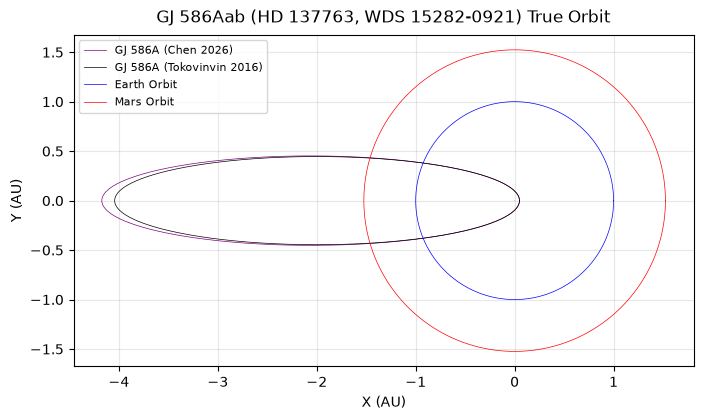

In [18]:
def plot_true_orbit(a, e, plx, num_points):
    # 1. Define orbital parameters
    a_true = a * 1000.0/plx # AU
    p = a_true * (1 - e**2)  # Semi-latus rectum

    # 2. Generate theta values
    theta = np.linspace(0, 2 * np.pi,  num_points)

    # 3. Calculate r for a focus-centered ellipse
    r = p / (1 + e * np.cos(theta))

    # --- Convert to Cartesian coordinates ---
    x = r * np.cos(theta)
    y = r * np.sin(theta)
    print(f'SMA: {a_true} AU\n  Periastron: {a_true*(1-e)} AU\n    Apastron: {a_true*(1+e)} AU')
    return x, y


# 4. Create the Cartesian plot
fig, ax = plt.subplots(figsize=(8, 8))



x_2016_true, y_2016_true = plot_true_orbit(a_2016/1000.0, e_2016, plx_2016, num_points)
x_test_true, y_test_true = plot_true_orbit(a, e, plx, num_points)

ax.plot(x_test_true, y_test_true, label='GJ 586A (Chen 2026)', color='purple', lw=0.5)
ax.plot(x_2016_true, y_2016_true, label='GJ 586A (Tokovinvin 2016)', color='black', lw=0.5)



x_earth = 1 * np.cos(np.linspace(0, 2*np.pi, num_points))
y_earth = 1 * np.sin(np.linspace(0, 2*np.pi, num_points)) 
ax.plot(x_earth, y_earth, color="blue", lw=0.5, label="Earth Orbit")

x_mars = 1.524 * np.cos(np.linspace(0, 2*np.pi, num_points)) 
y_mars = 1.524 * np.sin(np.linspace(0, 2*np.pi, num_points)) 
ax.plot(x_mars, y_mars, color="red", lw=0.5, label="Mars Orbit")

# Mark the primary star at the center (0,0)
Aa = plt.Circle((0, 0), 0.92*6.957e8/1.496e11, facecolor='orange')
ax.add_patch(Aa)

# Essential formatting for Cartesian geometry

#ax.set_ylim(-1, 1)
#ax.set_xlim(-1, 1)
ax.set_aspect('equal')  # Prevents the ellipse from looking distorted
ax.grid(alpha=0.3)

ax.set_xlabel('X (AU)')
ax.set_ylabel('Y (AU)')
ax.set_title(f"{target} True Orbit", va='bottom')

ax.legend(fontsize=8)


In [19]:
# PMOIRED chi2r Color Map Data 

# Taking any chi2r under 4
data1 = np.genfromtxt("PMOIRED_chi2r/2014_07_29_chi2r_sep_PA.csv", delimiter=",", skip_header=1, usecols = (0, 1, 2))

chi2r_1 = data1[:, 0]  
sep_1 = data1[:, 1]                
PA_deg_1 = data1[:, 2]   

PA_1 = np.deg2rad(PA_deg_1)

x_obs_1 = sep_1 * np.cos(PA_1)
y_obs_1 = sep_1 * np.sin(PA_1)


# Taking the first 1000 fits
data1 = np.genfromtxt("PMOIRED_chi2r/2014_07_26_chi2r_sep_PA.csv", delimiter=",", skip_header=1, usecols = (0, 1, 2))

chi2r_2 = data1[:, 0]  
sep_2 = data1[:, 1]                
PA_deg_2 = data1[:, 2]   

PA_2 = np.deg2rad(PA_deg_2)

x_obs_2 = sep_2 * np.cos(PA_2)
y_obs_2 = sep_2 * np.sin(PA_2)


# Min chi2r of 2014-7-29
min_chi2r_1 = np.min(chi2r_1)
sep_min_chi2r_1 = sep_1[np.argmin(chi2r_1)]
PA_min_chi2r_1 = PA_1[np.argmin(chi2r_1)]

# Min chi2r of 2014-7-26
min_chi2r_2 = np.min(chi2r_2)
sep_min_chi2r_2 = sep_2[np.argmin(chi2r_2)]
PA_min_chi2r_2 = PA_2[np.argmin(chi2r_2)]

<>:10: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:32: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:10: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:32: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
/var/folders/nr/zvh8_cm52rd2wbplkbs9qwyw0000gn/T/ipykernel_10100/3895380086.py:10: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  fig.colorbar(tcf2, ax=ax, shrink=0.8).set_label(r"Reduced $\chi^2$")
/var/folders/nr/zvh8_cm52rd2wbplkbs9qwyw0000gn/T/ipykernel_10100/3895380086.py:32: 

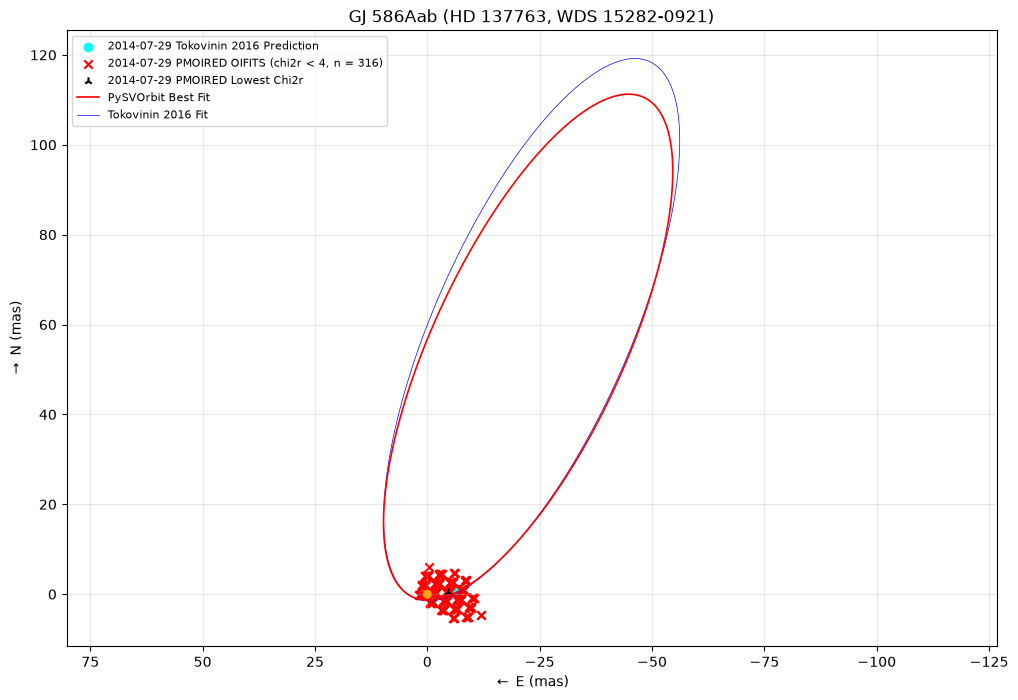

In [20]:
# PMOIRED Chi2r Plots
fig, ax = plt.subplots(figsize=(12, 8))

"""
# Color map of chi2r for 2014-7-26
tcf2 = ax.tricontourf(y_obs_2, x_obs_2, chi2r_2,
                     levels=15, cmap='viridis_r', alpha=0.8, zorder=1)
ax.tricontour(y_obs_2, x_obs_2, chi2r_2, levels=15,
              colors='k', linewidths=0.3, zorder=1)
fig.colorbar(tcf2, ax=ax, shrink=0.8).set_label(r"Reduced $\chi^2$")


# Plot 2014-7-26 TOkovinin 2016 Prediction
x_7_26, y_7_26 = sky_position_at_epoch(2014.565024, P_2016, T_2016, e_2016, a_2016, i_2016, omega_2016, Omega_2016)
ax.scatter(y_7_26, x_7_26, marker='o', color='cyan', label='2014-07-26 Tokovinin 2016 Prediction', zorder = 10)

# Plot PMOIRED fits for 2014-7-26
ax.scatter(y_obs_2, x_obs_2, marker = "x", color="blue", label="2014-07-26 PMOIRED OIFITS (Top 459 Fits given by PMOIRED)", zorder=11)

# Plot the best chi2r for 2014-7-26
ax.scatter(sep_min_chi2r_2*np.sin(PA_min_chi2r_2), sep_min_chi2r_2*np.cos(PA_min_chi2r_2), marker='2', color='black', label='2014-07-26 PMOIRED Lowest Chi2r')
"""


"""

# Color map of chi2r for 2014-7-29
tcf = ax.tricontourf(y_obs_1, x_obs_1, chi2r_1,
                     levels=15, cmap='viridis_r', alpha=0.8, zorder=1)
ax.tricontour(y_obs_1, x_obs_1, chi2r_1, levels=15,
              colors='k', linewidths=0.3, zorder=1)
fig.colorbar(tcf, ax=ax, shrink=0.8).set_label(r"Reduced $\chi^2$")
"""

# Plot 2014-7-29 TOkovinin 2016 Prediction
x_7_29, y_7_29 = sky_position_at_epoch(2014.573105, P_2016, T_2016, e_2016, a_2016, i_2016, omega_2016, Omega_2016)
ax.scatter(y_7_29, x_7_29, marker='o', color='cyan', label='2014-07-29 Tokovinin 2016 Prediction')


# Plot PMOIRED fits for 2014-7-29
ax.scatter(y_obs_1, x_obs_1, marker = "x", color="red", label="2014-07-29 PMOIRED OIFITS (chi2r < 4, n = 316)")

# Plot the best chi2r for 2014-7-29
ax.scatter(sep_min_chi2r_1*np.sin(PA_min_chi2r_1), sep_min_chi2r_1*np.cos(PA_min_chi2r_1), marker='2', color='black', label='2014-07-29 PMOIRED Lowest Chi2r')




# Zoom window. Change the limits and rerun only this cell.
centerx = -7.8
centery = 1
half_width = 1


"""
# --------------------------------------_
# Check for the PMOIRED 2014-7-29 Fits that are on the Monte-Carlo Orbits and Tokovinin 2016
# Keep 2014-07-29 rows with separation in [7, 9] mas and position angle in [260, 280] deg.
keep = (sep_1 >= 7) & (sep_1 <= 9) & (PA_deg_1 >= 265) & (PA_deg_1 <= 280)
chi2r_filt = chi2r_1[keep].tolist()
sep_filt = sep_1[keep].tolist()
PA_filt = PA_deg_1[keep].tolist()


# Same sky convention as the other PMOIRED points: East = sep*sin(PA), North = sep*cos(PA).
PA_filt_rad = np.deg2rad(PA_filt)
north_filt = np.array(sep_filt) * np.cos(PA_filt_rad)
east_filt = np.array(sep_filt) * np.sin(PA_filt_rad)
ax.scatter(east_filt, north_filt, marker="x", color="purple", label="2014-07-29 filtered")
# --------------------------------------_
"""


ax.plot(X_test, Y_test, color="red", lw=1.2, zorder=3, label="PySVOrbit Best Fit")
ax.plot(X_2016, Y_2016, color="blue", linestyle="-", lw=0.5, zorder=2, label="Tokovinin 2016 Fit")
ax.add_patch(plt.Circle((0, 0), 1, facecolor="orange"))
ax.set_aspect("equal", adjustable="datalim")
ax.invert_xaxis()  # East to the left, so the limits are written right-to-left

#ax.set_xlim(centerx + half_width, centerx - half_width)
#ax.set_ylim(centery - half_width, centery + half_width)

ax.grid(alpha=0.3)
ax.set_xlabel(r"$\leftarrow$ E (mas)")
ax.set_ylabel(r"$\rightarrow$ N (mas)")
ax.set_title(f"{target}")
ax.legend(fontsize=8, loc="upper left")
plt.show()
